# 7. Logistic Regression (Hồi quy Logistic)

## Lý thuyết & Nguyên lý

### 7.1. Từ đường thẳng tuyến tính đến xác suất — hàm Sigmoid

Logistic Regression "mượn" phần đầu của hồi quy tuyến tính $z = w^\top x + b$, rồi biến đổi kết quả $z \in (-\infty, +\infty)$ thành một **xác suất** nằm gọn trong $(0, 1)$ bằng hàm Sigmoid:

$$\sigma(z) = \frac{1}{1 + e^{-z}} \qquad \Rightarrow \qquad P(Y=1 \mid x) = \sigma(w^\top x + b)$$

- $z = 0 \Rightarrow \sigma = 0.5$ (bất định, ranh giới quyết định).
- $z \to +\infty \Rightarrow \sigma \to 1$; $z \to -\infty \Rightarrow \sigma \to 0$.
- Tính chất đẹp: $\sigma'(z) = \sigma(z)\,(1 - \sigma(z))$ — đạo hàm rất gọn, hỗ trợ tối ưu bằng gradient descent.

Ranh giới quyết định ở ngưỡng 0.5 tương ứng với siêu phẳng $w^\top x + b = 0$. Hệ số $w_j$ có thể diễn giải qua **Odds Ratio**: $e^{w_j}$ là tỉ lệ thay đổi của odds khi $x_j$ tăng 1 đơn vị (giữ các biến còn lại không đổi).

### 7.2. Hàm mất mát — Binary Cross-Entropy (Log Loss)

Không dùng MSE (sai số bình phương) vì mất mát sẽ **không lồi** (non-convex) khi hàm liên kết là sigmoid → dễ rơi vào điểm tối ưu cục bộ. Thay vào đó dùng **Log Loss**, bắt nguồn từ phương pháp ước lượng cực đại xác suất likelihood (MLE):

$$\text{Log Loss} = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \log(\hat{y}_i) + (1 - y_i)\log(1 - \hat{y}_i)\Big]$$

- Nếu $y_i = 1$ và $\hat{y}_i \to 0$ (dự đoán sai tự tin) → mất mát $\to +\infty$ (phạt nặng).
- Mất mát này **lồi** → gradient descent đảm bảo tìm được nghiệm toàn cục.

### 7.3. Đăng ký chính quy hóa và đa lớp

- scikit-learn dùng tham số `C` = **nghịch đảo** của $\lambda$ (hệ số phạt): `C` lớn → ít phạt (dễ overfit), `C` nhỏ → phạt mạnh (giống Ridge/Lasso). Có thể chọn `penalty='l1'` để thực hiện chọn lọc đặc trưng.
- **Đa lớp (multi-class):** softmax regression — $P(Y=k \mid x) = \dfrac{e^{w_k^\top x}}{\sum_{j} e^{w_j^\top x}}$ (mặc định `multi_class='auto'` dùng OvR hoặc multinomial tùy solver).

### 7.4. Giới hạn

Logistic Regression chỉ vẽ được **ranh giới tuyến tính** (đường thẳng/phẳng) — với dữ liệu không tách tuyến tính (ví dụ vòng tròn), cần **thủ công tạo đặc trưng phi tuyến** (polynomial features) hoặc chuyển sang SVM/GBM.


z = -3  ->  sigma(z) = 0.0474
z = -1  ->  sigma(z) = 0.2689
z = +0  ->  sigma(z) = 0.5000
z = +1  ->  sigma(z) = 0.7311
z = +3  ->  sigma(z) = 0.9526


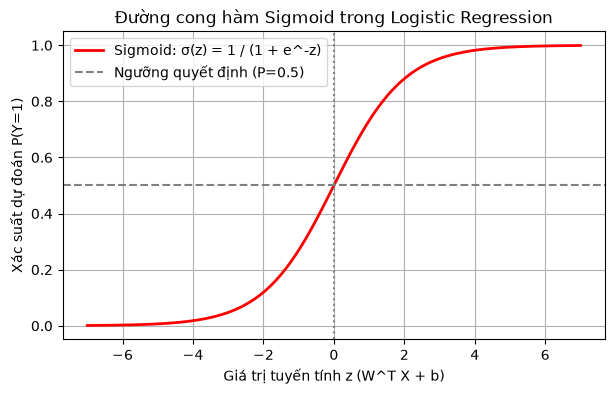

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Sinh trục z và tính xác suất qua hàm Sigmoid
z = np.linspace(-7, 7, 200)
sigmoid = 1 / (1 + np.exp(-z))

# 2. Vẽ đường cong sigmoid
plt.figure(figsize=(7, 4))
plt.plot(z, sigmoid, color='red', linewidth=2, label='Sigmoid: σ(z) = 1 / (1 + e^-z)')
plt.axhline(0.5, color='gray', linestyle='--', label='Ngưỡng quyết định (P=0.5)')
plt.axvline(0, color='gray', linestyle=':')
plt.title('Đường cong hàm Sigmoid trong Logistic Regression')
plt.xlabel('Giá trị tuyến tính z (W^T X + b)')
plt.ylabel('Xác suất dự đoán P(Y=1)')
plt.legend()
plt.grid(True)
plt.show()

# 3. Minh họa vài điểm đặc biệt trên đường cong
for z0 in [-3, -1, 0, 1, 3]:
    print(f"z = {z0:+d}  ->  sigma(z) = {1 / (1 + np.exp(-z0)):.4f}")


## Ý nghĩa của biểu đồ

- Đường cong chữ **S** đỏ là hàm sigmoid: mượt, đối xứng qua điểm $(0, 0.5)$, chuyển tiếp êm từ 0 sang 1.
- Vùng **bẹt hai đầu** (gần 0 và gần 1): mô hình "rất tự tin" — đạo hàm gần 0, gradient descent hầu như không cập nhật thêm → đây là lý do Log Loss (không phải MSE) được dùng để giữ gradient mạnh khi dự đoán sai.
- Ngưỡng 0.5 (đứt xám) là quy ước phổ biến; **có thể thay đổi ngưỡng** để điều chỉnh độ nhạy giữa Precision và Recall theo yêu cầu bài toán.

---

## Tổng quan mô hình

### Ưu điểm

- **Rất nhanh, nhẹ, huấn luyện hội tụ** — là baseline mặc định cho bài toán phân loại tuyến tính.
- **Dễ diễn giải:** hệ số $w_j$ cho biết mức độ và hướng ảnh hưởng của từng đặc trưng (qua Odds Ratio $e^{w_j}$).
- **Rất ít overfitting** khi kết hợp chính quy hóa L1/L2; hoạt động tốt với dữ liệu nhỏ, số chiều cao.
- **Đưa ra xác suất** có ý nghĩa (nếu dữ liệu thực sự tuân theo mô hình tuyến tính-độ dốc — mô hình được hiệu chuẩn tốt).
- **Mất mát lồi** → nghiệm toàn cục duy nhất, không sợ local minima.

### Nhược điểm

- **Chỉ ranh giới tuyến tính** — không học được quan hệ phi tuyến (cần polynomial features hoặc chuyển mô hình).
- **Nhạy cảm với điểm ngoại lai** (như mọi mô hình tham số tuyến tính).
- **Yêu cầu đặc trưng không tương quan mạnh** (multicollinearity làm hệ số không ổn định).
- **Hiệu năng kém trên dữ liệu không tuyến tính** hoặc có tương tác phức tạp giữa đặc trưng.

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `C` | Đảo ngược độ chính quy hóa ($C = 1/\lambda$) | 0.01–10 (đa số); quét theo thang log |
| `penalty` | 'l2' (mặc định), 'l1', 'elasticnet' | L1 khi cần chọn lọc đặc trưng |
| `solver` | 'lbfgs' (mặc định), 'liblinear', 'saga', 'newton-cg' | lbfgs cho L2 & đa lớp; liblinear/saga cho L1 |
| `max_iter` | Số vòng lặp tối ưu | Tăng lên nếu cảnh báo 'ConvergenceWarning' |
| `class_weight` | Cân bằng trọng số lớp | Dùng `class_weight='balanced'` khi dữ liệu lệch lớp |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Nhãn ($Y$) |
| :--- | :--- | :--- | :--- |
| **Tài chính** | Chấm điểm tín dụng | Thu nhập, nợ, lịch sử trả nợ | Có nợ xấu (1) / không (0) |
| **Y tế** | Sàng lọc bệnh | Tuổi, huyết áp, chỉ số xét nghiệm | Có bệnh (1) / khỏe (0) |
| **Marketing** | Dự đoán khách hàng bấm quảng cáo | Sở thích, lịch sử click, nhân khẩu | Click (1) / không click (0) |
| **Bảo hiểm** | Dự đoán khiếu nại | Tuổi xe, lịch sử lái, khu vực | Nảy sinh bồi thường (1/0) |
| **Công nghệ** | Phát hiện spam email | Tần suất từ khóa, người gửi, định dạng | Spam (1) / không (0) |

### Mẹo thực hành

- **Luôn chuẩn hóa/standardize** trước khi huấn luyện — hệ số Logistic Regression so sánh được giữa các đặc trưng chỉ khi cùng thang.
- Kiểm tra tương quan cao giữa các đặc trưng (VIF) — nếu có, dùng Ridge (L2) để ổn định hệ số.
- So sánh xác suất dự đoán với tần suất thực tế (calibration plot) nếu mô hình được dùng để ra quyết định dựa trên xác suất.


Accuracy : 0.9444
Log Loss : 0.1405
Confusion Matrix:
[[44  3]
 [ 2 41]]
Trọng số w: [4.032 0.446] | Bias b: 0.025


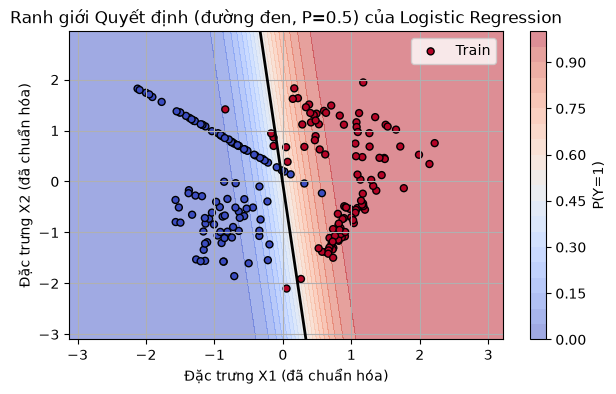

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Tạo dữ liệu 2 chiều (dễ trực quan hóa ranh giới)
X, y = make_classification(
    n_samples=300, n_features=2, n_redundant=0, n_informative=2,
    class_sep=1.2, random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. Chuẩn hóa + huấn luyện Logistic Regression
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
model = LogisticRegression().fit(X_train_s, y_train)

# 3. Đánh giá
y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Log Loss : {log_loss(y_test, y_prob):.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"Trọng số w: {model.coef_[0].round(3)} | Bias b: {model.intercept_[0]:.3f}")

# 4. Vẽ ranh giới quyết định + nền xác suất
xx, yy = np.meshgrid(
    np.linspace(X_train_s[:, 0].min() - 1, X_train_s[:, 0].max() + 1, 300),
    np.linspace(X_train_s[:, 1].min() - 1, X_train_s[:, 1].max() + 1, 300),
)
Z = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

plt.figure(figsize=(7, 4))
plt.contourf(xx, yy, Z, levels=20, cmap='coolwarm', alpha=0.5)
plt.colorbar(label='P(Y=1)')
plt.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=2)
plt.scatter(X_train_s[:, 0], X_train_s[:, 1], c=y_train, cmap='coolwarm',
            edgecolor='k', s=25, label='Train')
plt.title('Ranh giới Quyết định (đường đen, P=0.5) của Logistic Regression')
plt.xlabel('Đặc trưng X1 (đã chuẩn hóa)')
plt.ylabel('Đặc trưng X2 (đã chuẩn hóa)')
plt.legend()
plt.grid(True)
plt.show()


## Giải thích kết quả

- **Màu nền** thể hiện xác suất $P(Y=1)$ dự đoán bởi mô hình — chuyển dần đều từ xanh (gần 0) sang đỏ (gần 1), minh chứng sigmoid áp lên mặt phẳng tuyến tính.
- **Đường đen** là đường đồng mức 0.5 — **hoàn toàn là một đường thẳng**, đúng bản chất tuyến tính của Logistic Regression.
- Nhãn in ra cho thấy: các hệ số $w$ của mô hình sau khi chuẩn hóa có thể so sánh trực tiếp để đánh giá mức độ quan trọng của từng đặc trưng; `log_loss` thấp xác nhận mô hình không chỉ đúng (accuracy) mà còn **tự tin đúng** (dự đoán xác sát với nhãn thật).
